# Film Similarity and Clustering

Loads the processed feature outputs from the previous stage and uses them to:

- compute similarity between films
- test clustering solutions
- evaluate cluster quality
- interpret the resulting clusters
- visualize the film space in two dimensions

The goal is not only to produce clusters, but to identify groups that are coherent and interpretable.

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

# new

In [2]:
from pathlib import Path
from collections import Counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap.umap_ as umap

from scipy.sparse import hstack, load_npz
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

c:\Users\Georg\miniconda3\envs\fataEnv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the saved outputs

We load the processed dataframe, the fitted transformers, and the saved feature matrices from the previous notebook.

In [3]:
PROJECT_ROOT = Path.cwd().parents[1]

OUTPUTS_DIR = PROJECT_ROOT / "outputs" / "text_clustering"
FEATURES_DIR = OUTPUTS_DIR / "features"
RESULTS_DIR = OUTPUTS_DIR / "results"

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PROCESSED_PATH = FEATURES_DIR / "processed_films.csv"

TFIDF_VECTORIZER_PATH = FEATURES_DIR / "tfidf_vectorizer.joblib"
GENRE_MLB_PATH = FEATURES_DIR / "genre_mlb.joblib"
KEYWORD_MLB_PATH = FEATURES_DIR / "keyword_mlb.joblib"
METADATA_OHE_PATH = FEATURES_DIR / "metadata_ohe.joblib"

X_PLOT_TFIDF_PATH = FEATURES_DIR / "X_plot_tfidf.npz"
X_GENRES_PATH = FEATURES_DIR / "X_genres.npz"
X_KEYWORDS_PATH = FEATURES_DIR / "X_keywords.npz"
X_METADATA_PATH = FEATURES_DIR / "X_metadata.npz"
X_PLOT_ONLY_PATH = FEATURES_DIR / "X_plot_only.npz"
X_FULL_BASELINE_PATH = FEATURES_DIR / "X_full_baseline.npz"

In [4]:
df = pd.read_csv(PROCESSED_PATH)

tfidf_vectorizer = joblib.load(TFIDF_VECTORIZER_PATH)
genre_mlb = joblib.load(GENRE_MLB_PATH)
keyword_mlb = joblib.load(KEYWORD_MLB_PATH)
metadata_ohe = joblib.load(METADATA_OHE_PATH)

X_plot_tfidf = load_npz(X_PLOT_TFIDF_PATH)
X_genres = load_npz(X_GENRES_PATH)
X_keywords = load_npz(X_KEYWORDS_PATH)
X_metadata = load_npz(X_METADATA_PATH)
X_plot_only = load_npz(X_PLOT_ONLY_PATH)
X_full_baseline = load_npz(X_FULL_BASELINE_PATH)

print("DataFrame shape:", df.shape)
print("X_plot_tfidf:", X_plot_tfidf.shape)
print("X_genres:", X_genres.shape)
print("X_keywords:", X_keywords.shape)
print("X_metadata:", X_metadata.shape)
print("X_plot_only:", X_plot_only.shape)
print("X_full_baseline:", X_full_baseline.shape)

DataFrame shape: (2000, 15)
X_plot_tfidf: (2000, 3946)
X_genres: (2000, 24)
X_keywords: (2000, 9327)
X_metadata: (2000, 74)
X_plot_only: (2000, 3946)
X_full_baseline: (2000, 13371)


In [5]:
if "title" in df.columns:
    display_col = "title"
else:
    display_col = df.columns[0]

print("Display column:", display_col)
df[[display_col]].head()

Display column: plotMedium


,plotMedium
0,"Poland, 1962. Anna, an orphan brought up by nu..."
1,Loosely-based on the true events of a homeless...
2,"Louis, a young teacher enamored of the age of ..."
3,"An outlandish science-fiction, comedy-thriller..."
4,"Mrs. Palfrey (Dame Joan Plowright), recently w..."


## 2. Build the matrices to compare

We keep:
- a plot-only representation
- a hybrid representation
- an optional weighted hybrid representation where narrative text has more influence than metadata

In [6]:
PLOT_WEIGHT = 0.85
GENRE_WEIGHT = 0.55
KEYWORD_WEIGHT = 0.55
METADATA_WEIGHT = 0.20

# Normalize each block first so one block does not dominate the others
X_plot_block = normalize(X_plot_tfidf, norm="l2", axis=1)
X_genres_block = normalize(X_genres, norm="l2", axis=1)
X_keywords_block = normalize(X_keywords, norm="l2", axis=1)
X_metadata_block = normalize(X_metadata, norm="l2", axis=1)

X_plot_only_current = X_plot_block.tocsr()

X_full_baseline_current = hstack([
    X_plot_block,
    X_genres_block,
    X_keywords_block,
    X_metadata_block
]).tocsr()

X_hybrid_weighted = hstack([
    X_plot_block * PLOT_WEIGHT,
    X_genres_block * GENRE_WEIGHT,
    X_keywords_block * KEYWORD_WEIGHT,
    X_metadata_block * METADATA_WEIGHT
]).tocsr()

print("Plot-only current:", X_plot_only_current.shape)
print("Full baseline current:", X_full_baseline_current.shape)
print("Weighted hybrid matrix:", X_hybrid_weighted.shape)

Plot-only current: (2000, 3946)
Full baseline current: (2000, 13371)
Weighted hybrid matrix: (2000, 13371)


In [7]:
matrix_options = {
    "plot_only": X_plot_only_current,
    "full_baseline": X_full_baseline_current,
    "weighted_hybrid": X_hybrid_weighted,
}

In [8]:
def prepare_matrix_for_clustering(matrix, n_components=150, random_state=42):
    X_norm = normalize(matrix, norm="l2", axis=1)

    max_components = min(X_norm.shape[0] - 1, X_norm.shape[1] - 1, n_components)
    if max_components < 2:
        raise ValueError("Not enough dimensions for TruncatedSVD.")

    svd = TruncatedSVD(n_components=max_components, random_state=random_state)
    X_reduced = svd.fit_transform(X_norm)
    X_reduced = normalize(X_reduced, norm="l2")
    

    explained_var = float(svd.explained_variance_ratio_.sum())
    return X_reduced, svd, explained_var

## 3. Compute film similarity

Cosine similarity is used because it works well with TF-IDF and sparse vectors and it is easy to interpret.

In [9]:
def get_top_similar_films(matrix, film_index, df, title_col, top_n=5):
    similarity_vector = cosine_similarity(matrix[film_index], matrix).flatten()
    ranked_indices = np.argsort(similarity_vector)[::-1]

    results = []
    for idx in ranked_indices:
        if idx == film_index:
            continue

        results.append({
            "film_index": int(idx),
            "title": df.iloc[idx][title_col],
            "similarity": float(similarity_vector[idx]),
        })

        if len(results) >= top_n:
            break

    return pd.DataFrame(results)

In [10]:
example_index = 0
get_top_similar_films(
    matrix=X_hybrid_weighted,
    film_index=example_index,
    df=df,
    title_col=display_col,
    top_n=5
)

,film_index,title,similarity
0,378,"Poland, 1962. Anna, an orphan brought up by nu...",1.000000
1,1401,"Poland, 1962. Anna, an orphan brought up by nu...",1.000000
2,991,"In the 1930s, the feeble-minded Sven's mother ...",0.329863
3,281,"In 1874, in the Imperial Russia, the aristocra...",0.305679
4,203,"Hungary, 1943. An elderly Jewish couple, Job a...",0.302898


In [11]:
def find_film_index_by_title(df, title_col, query):
    matches = df[df[title_col].astype(str).str.contains(query, case=False, na=False)]
    return matches[[title_col]].head(10), matches.index.tolist()


matches_df, match_indices = find_film_index_by_title(df, display_col, "love")
matches_df

,plotMedium
8,"Paralyzing, tormenting and overwhelming. Often..."
20,The deranged Roman emperor Gainus 'Caligula' (...
23,An urgent life-or-death dilemma befalls Nikita...
27,"Based on the book by famous sport journalist, ..."
31,"In Dublin, the disabled rebel Rory O'Shea move..."
36,It's already been three months since the sudde...
61,"Set in a lush fantasy world, the film follows ..."
69,"For 20 years, many visitors have come to the v..."
76,"'Paris, Je T'aime] is about the plurality of c..."
78,In Biarritz with her elderly provider to celeb...


In [12]:
selected_index = match_indices[0]
get_top_similar_films(
    matrix=X_hybrid_weighted,
    film_index=selected_index,
    df=df,
    title_col=display_col,
    top_n=5
)

,film_index,title,similarity
0,11,Anton is a doctor who commutes between his hom...,0.247971
1,1122,Berlin student Jule is hopelessly indebted fro...,0.241070
2,265,A boy who grew up in a native Sicilian Village...,0.236845
3,1638,A member of Parliament (Irons) falls passionat...,0.231281
4,148,Almut (Florence Pugh) and Tobias (Andrew Garfi...,0.230686


## 4. Evaluate clustering solutions

We start with KMeans as the baseline clustering method and test several values of k.

We evaluate each solution using:
- silhouette score
- cluster size balance
- interpretability

In [13]:
from threadpoolctl import threadpool_limits
import pandas as pd
import numpy as np
import time
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

def evaluate_kmeans_solutions(
    matrix,
    k_values,
    random_state=42,
    n_init=3,
    n_components=30,
    eval_sample_size=400,
    silhouette_sample_size=200
):
    rng = np.random.default_rng(random_state)

    n_rows = matrix.shape[0]
    sample_n = min(eval_sample_size, n_rows)

    sampled_idx = np.sort(rng.choice(n_rows, size=sample_n, replace=False))
    matrix_sample = matrix[sampled_idx]

    t0 = time.perf_counter()
    with threadpool_limits(limits=1):
        X_for_clustering, svd_model, explained_var = prepare_matrix_for_clustering(
            matrix_sample,
            n_components=n_components,
            random_state=random_state
        )
    print(f"SVD done in {time.perf_counter() - t0:.2f}s")

    results = []

    with threadpool_limits(limits=1):
        for k in k_values:
            t_k = time.perf_counter()

            model = MiniBatchKMeans(
                n_clusters=k,
                random_state=random_state,
                n_init=n_init,
                batch_size=256,
                max_iter=100,
                reassignment_ratio=0.01
            )

            labels = model.fit_predict(X_for_clustering)

            silhouette = silhouette_score(
                X_for_clustering,
                labels,
                sample_size=min(silhouette_sample_size, len(labels)),
                random_state=random_state
            )

            cluster_sizes = pd.Series(labels).value_counts().sort_index()

            results.append({
                "k": k,
                "silhouette_score": float(silhouette),
                "min_cluster_size": int(cluster_sizes.min()),
                "max_cluster_size": int(cluster_sizes.max()),
                "mean_cluster_size": float(cluster_sizes.mean()),
                "imbalance_ratio": float(cluster_sizes.max() / cluster_sizes.min()),
                "svd_explained_variance": explained_var,
                "evaluation_rows_used": int(sample_n),
                "inertia": model.inertia_
            })

            print(f"k={k} done in {time.perf_counter() - t_k:.2f}s")

    return pd.DataFrame(results).sort_values(
        ["imbalance_ratio", "silhouette_score"],
        ascending=[True, False]
    ).reset_index(drop=True)
    
    
    # new

In [14]:
from scipy.sparse import issparse

print(type(matrix_options["weighted_hybrid"]))
print("is sparse:", issparse(matrix_options["weighted_hybrid"]))
print("shape:", matrix_options["weighted_hybrid"].shape)

# new

<class 'scipy.sparse._csr.csr_matrix'>
is sparse: True
shape: (2000, 13371)


In [15]:
K_VALUES = [4, 5, 6, 7, 8]

evaluation_weighted = evaluate_kmeans_solutions(
    matrix_options["weighted_hybrid"],
    K_VALUES,
    n_init=3,
    n_components=30,
    eval_sample_size=400,
    silhouette_sample_size=200
)

print("Weighted hybrid evaluation")
display(evaluation_weighted)

# new

SVD done in 0.26s
k=4 done in 0.04s
k=5 done in 0.01s
k=6 done in 0.01s
k=7 done in 0.01s
k=8 done in 0.01s
Weighted hybrid evaluation


,k,silhouette_score,min_cluster_size,max_cluster_size,mean_cluster_size,imbalance_ratio,svd_explained_variance,evaluation_rows_used,inertia
0,4,0.122788,79,143,100.000000,1.810127,0.273364,400,224.965342
1,7,0.100252,41,77,57.142857,1.878049,0.273364,400,198.360332
2,5,0.130179,56,128,80.000000,2.285714,0.273364,400,210.376699
3,8,0.116006,27,69,50.000000,2.555556,0.273364,400,185.261625
4,6,0.121717,33,106,66.666667,3.212121,0.273364,400,203.195161


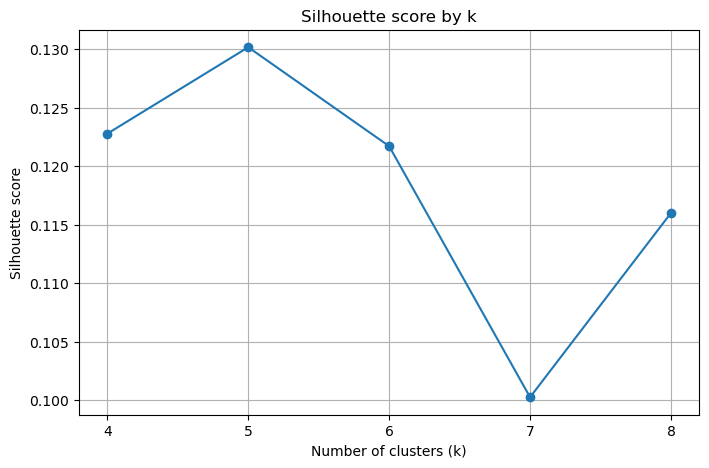

In [16]:
import matplotlib.pyplot as plt

eval_plot = evaluation_weighted.sort_values("k")

plt.figure(figsize=(8, 5))
plt.plot(eval_plot["k"], eval_plot["silhouette_score"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score by k")
plt.xticks(eval_plot["k"])
plt.grid(True)
plt.show()

# new

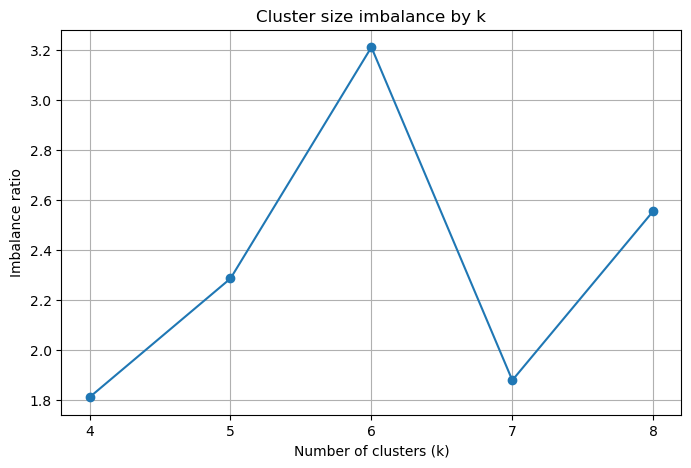

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(eval_plot["k"], eval_plot["imbalance_ratio"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Imbalance ratio")
plt.title("Cluster size imbalance by k")
plt.xticks(eval_plot["k"])
plt.grid(True)
plt.show()

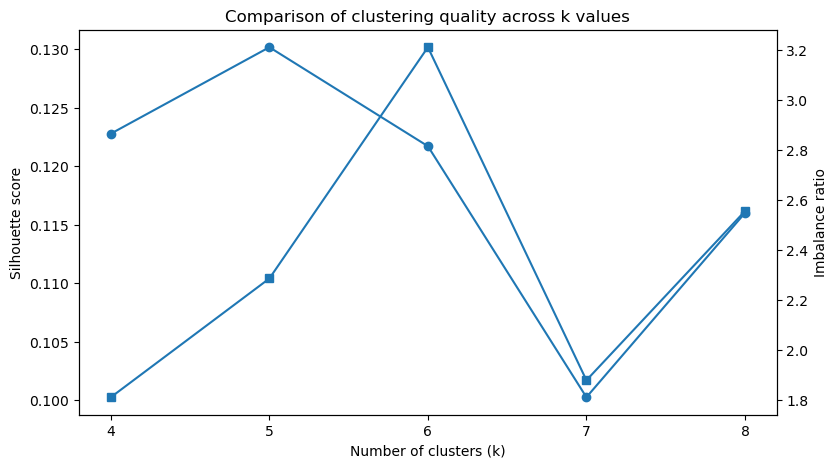

In [18]:
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(eval_plot["k"], eval_plot["silhouette_score"], marker="o")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Silhouette score")

ax2 = ax1.twinx()
ax2.plot(eval_plot["k"], eval_plot["imbalance_ratio"], marker="s")
ax2.set_ylabel("Imbalance ratio")

plt.title("Comparison of clustering quality across k values")
plt.xticks(eval_plot["k"])
plt.show()

## 5. Fit the selected clustering model

After comparing several values of k, we select one clustering solution for detailed interpretation.

The final choice should not depend only on the score. The clusters should also be coherent and describable.

In [19]:
FINAL_MATRIX_NAME = "weighted_hybrid"
FINAL_K = 6
SVD_COMPONENTS = 150

X_model = matrix_options[FINAL_MATRIX_NAME]
X_model_for_clustering, svd_model, explained_var = prepare_matrix_for_clustering(
    X_model,
    n_components=SVD_COMPONENTS,
    random_state=42
)

kmeans_model = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10,           # Το κατέβασα από το 30 (είναι περιττό)
    max_iter=300,
    algorithm="elkan"    # Προσθήκη
)

with threadpool_limits(limits=1, user_api='blas'):
    cluster_labels = kmeans_model.fit_predict(X_model_for_clustering)
df["cluster"] = cluster_labels

print("Selected matrix:", FINAL_MATRIX_NAME)
print("Selected k:", FINAL_K)
print(f"SVD explained variance: {explained_var:.3f}")
print(df["cluster"].value_counts().sort_index())

Selected matrix: weighted_hybrid
Selected k: 6
SVD explained variance: 0.373
cluster
0    361
1    392
2    290
3    374
4    294
5    289
Name: count, dtype: int64


## 6. Inspect cluster sizes

A useful first check is whether the final clustering solution produces reasonably balanced groups.

In [20]:
cluster_size_df = (
    df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="count")
)

cluster_size_df

,cluster,count
0,0,361
1,1,392
2,2,290
3,3,374
4,4,294
5,5,289


## 7. Build cluster profiles

The goal is not only to assign films to clusters, but to describe each cluster in human terms.

For each cluster, we inspect:
- top TF-IDF terms
- most common genres
- most common keywords
- dominant country
- dominant language
- representative films

In [21]:
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()
n_tfidf_features = X_plot_tfidf.shape[1]

In [22]:
def top_terms_from_cluster_mean(X_tfidf, labels, cluster_id, feature_names, top_n=10):
    cluster_rows = X_tfidf[labels == cluster_id]
    mean_vector = np.asarray(cluster_rows.mean(axis=0)).ravel()
    top_idx = np.argsort(mean_vector)[::-1][:top_n]
    return [feature_names[i] for i in top_idx]

In [23]:
def most_common_list_items(series, top_n=10):
    counter = Counter()

    for value in series.dropna():
        if isinstance(value, str):
            try:
                parsed = eval(value) if value.startswith("[") and value.endswith("]") else None
                if isinstance(parsed, list):
                    counter.update(parsed)
                else:
                    continue
            except:
                continue
        elif isinstance(value, list):
            counter.update(value)

    return counter.most_common(top_n)

In [24]:
import ast

def parse_saved_list(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    text = str(value).strip()
    if text == "":
        return []

    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, list):
            return parsed
    except:
        pass

    return []

In [25]:
df["genres_list_parsed"] = df["genres_list"].apply(parse_saved_list) if "genres_list" in df.columns else [[] for _ in range(len(df))]
df["keywords_filtered_parsed"] = df["keywords_filtered"].apply(parse_saved_list) if "keywords_filtered" in df.columns else [[] for _ in range(len(df))]

In [26]:
def get_representative_films(matrix, model, labels, cluster_id, df, title_col, top_n=5):
    distances_to_centers = model.transform(matrix)
    cluster_indices = np.where(labels == cluster_id)[0]
    cluster_distances = distances_to_centers[cluster_indices, cluster_id]

    ranked_local = np.argsort(cluster_distances)[:top_n]
    representative_indices = cluster_indices[ranked_local]

    return df.iloc[representative_indices][[title_col]].reset_index(drop=True)

In [27]:
cluster_profiles = []

for cluster_id in sorted(df["cluster"].unique()):
    cluster_df = df[df["cluster"] == cluster_id].copy()

    top_terms = top_terms_from_cluster_mean(
        X_plot_tfidf,
        cluster_labels,
        cluster_id,
        tfidf_feature_names,
        top_n=10
    )

    genre_counter = Counter()
    for items in cluster_df["genres_list_parsed"]:
        genre_counter.update(items)

    keyword_counter = Counter()
    for items in cluster_df["keywords_filtered_parsed"]:
        keyword_counter.update(items)

    dominant_country = cluster_df["mainCountry_clean"].mode().iloc[0] if "mainCountry_clean" in cluster_df.columns and not cluster_df["mainCountry_clean"].mode().empty else "unknown"
    dominant_language = cluster_df["firstLanguage_clean"].mode().iloc[0] if "firstLanguage_clean" in cluster_df.columns and not cluster_df["firstLanguage_clean"].mode().empty else "unknown"

    representative_films = get_representative_films(
        matrix=X_model_for_clustering,
        model=kmeans_model,
        labels=cluster_labels,
        cluster_id=cluster_id,
        df=df,
        title_col=display_col,
        top_n=5
    )[display_col].tolist()

    cluster_profiles.append({
        "cluster": cluster_id,
        "size": int(len(cluster_df)),
        "top_terms": ", ".join(top_terms[:8]),
        "top_genres": ", ".join([g for g, _ in genre_counter.most_common(5)]),
        "top_keywords": ", ".join([k for k, _ in keyword_counter.most_common(5)]),
        "dominant_country": dominant_country,
        "dominant_language": dominant_language,
        "representative_films": " | ".join(representative_films),
    })

cluster_profiles_df = pd.DataFrame(cluster_profiles)
cluster_profiles_df

,cluster,size,top_terms,top_genres,top_keywords,dominant_country,dominant_language,representative_films
0,0,361,"house, night, soon, blood, dr, mysterious, gro...","horror, thriller, mystery, drama, sci-fi","murder, blood, psychotronic film, death, violence",gb,en,A young psychiatrist interviews four inmates i...
1,1,392,"war, mother, year, film, old, father, people, ...","drama, history, biography, war, crime","based on true story, murder, husband wife rela...",gb,en,Upon his father's death. Jake revisits the wor...
2,2,290,"friends, just, friend, best, town, father, sch...","comedy, drama, romance, crime, action","female nudity, husband wife relationship, inde...",gb,en,Professors Vooshka and Crump decide to visit a...
3,3,374,"police, soon, wife, daughter, death, finds, de...","thriller, drama, crime, mystery, action","murder, death, violence, blood, female nudity",gb,en,"Harold (Bob Hoskins), a prosperous English gan..."
4,4,294,"old, meets, wife, mother, relationship, husban...","romance, drama, comedy, biography, thriller","kiss, husband wife relationship, female nudity...",gb,en,Sonia is a member of a closed Hasidic communit...
5,5,289,"bond, help, mission, friends, father, named, j...","adventure, fantasy, family, comedy, action","explosion, murder, rescue, character name in t...",gb,en,Jason has been prophesied to take the throne o...


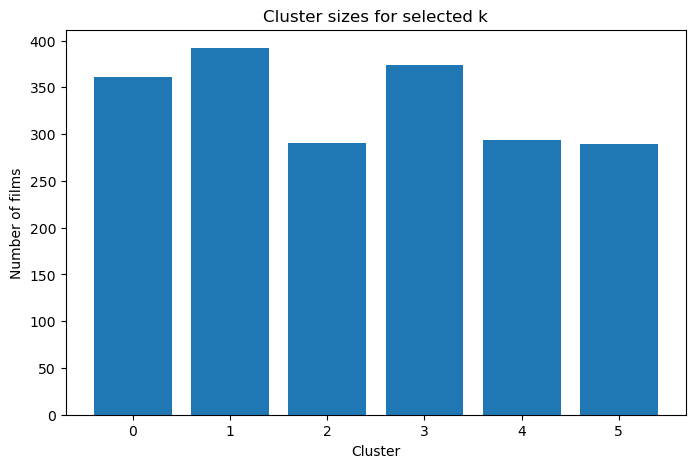

In [28]:
import matplotlib.pyplot as plt

cluster_profiles = cluster_profiles_df.sort_values("cluster")

plt.figure(figsize=(8, 5))
plt.bar(cluster_profiles["cluster"].astype(str), cluster_profiles["size"])
plt.xlabel("Cluster")
plt.ylabel("Number of films")
plt.title("Cluster sizes for selected k")
plt.show()

In [29]:
display(
    eval_plot[["k", "silhouette_score", "imbalance_ratio", "min_cluster_size", "max_cluster_size", "inertia"]]
)

,k,silhouette_score,imbalance_ratio,min_cluster_size,max_cluster_size,inertia
0,4,0.122788,1.810127,79,143,224.965342
2,5,0.130179,2.285714,56,128,210.376699
4,6,0.121717,3.212121,33,106,203.195161
1,7,0.100252,1.878049,41,77,198.360332
3,8,0.116006,2.555556,27,69,185.261625


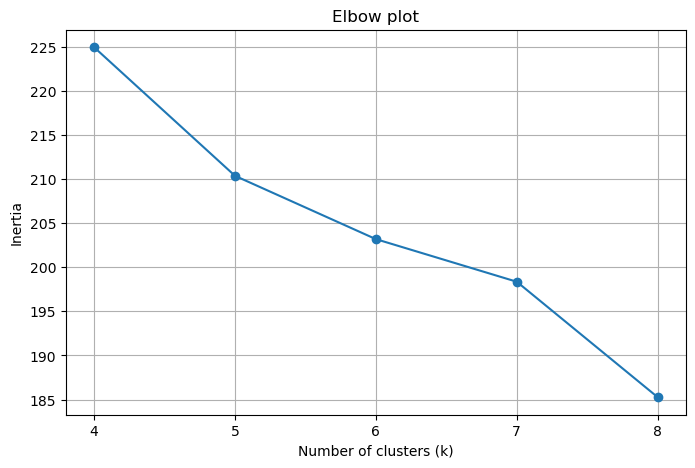

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(eval_plot["k"], eval_plot["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow plot")
plt.xticks(eval_plot["k"])
plt.grid(True)
plt.show()

## 8. Visualize the clustering solution with UMAP

To complement the baseline clustering analysis, we use UMAP to project the selected feature space into two dimensions.

This visualization helps us inspect whether the final clusters appear compact, overlapping, or well separated in the embedded space.

In [31]:
umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.10,
    n_components=2,
    metric="cosine",
    random_state=42,
    low_memory=True,
    output_dens=False
)

X_umap_2d = umap_model.fit_transform(X_model_for_clustering)

if isinstance(X_umap_2d, tuple):
    X_umap_2d = X_umap_2d[0]

X_umap_2d = np.asarray(X_umap_2d)

print(type(X_umap_2d))
print(X_umap_2d.shape)

c:\Users\Georg\miniconda3\envs\fataEnv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<class 'numpy.ndarray'>
(2000, 2)


In [32]:
umap_df = pd.DataFrame({
    "x": X_umap_2d[:, 0],
    "y": X_umap_2d[:, 1],
    "cluster": cluster_labels,
    "title": df[display_col].astype(str)
})

umap_df.head()

,x,y,cluster,title
0,-2.127399,-4.099079,1,"Poland, 1962. Anna, an orphan brought up by nu..."
1,6.919520,0.612094,0,Loosely-based on the true events of a homeless...
2,0.692145,6.341920,2,"Louis, a young teacher enamored of the age of ..."
3,2.724645,2.903411,2,"An outlandish science-fiction, comedy-thriller..."
4,0.722012,4.121654,2,"Mrs. Palfrey (Dame Joan Plowright), recently w..."


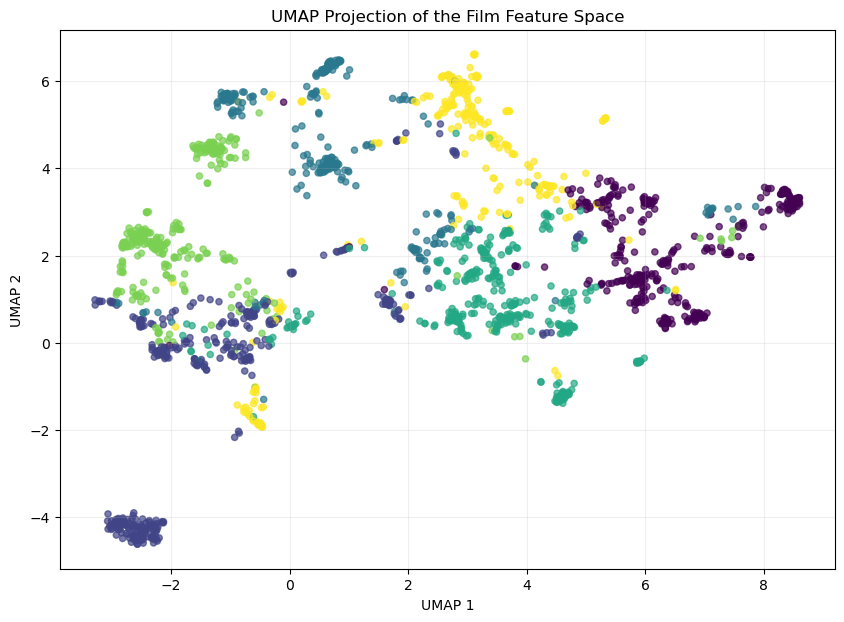

In [33]:
plt.figure(figsize=(10, 7))

plt.scatter(
    umap_df["x"],
    umap_df["y"],
    c=umap_df["cluster"],
    s=20,
    alpha=0.7
)

plt.title("UMAP Projection of the Film Feature Space")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.grid(alpha=0.2)
plt.show()

In [34]:
umap_projection_path = RESULTS_DIR / "umap_projection.csv"
umap_df.to_csv(umap_projection_path, index=False)

print("Saved UMAP projection to:", umap_projection_path)

Saved UMAP projection to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\umap_projection.csv


In [35]:
umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.10,
    n_components=2,
    metric="cosine",
    random_state=42,
    
    low_memory=True
)

## 9. Visualize the film space in 2D

For a simple baseline view, we project the sparse feature space into two dimensions.

Since the feature matrix is sparse, we use TruncatedSVD as a practical PCA-style approximation.

In [36]:
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd_2d.fit_transform(X_model_for_clustering)

plot_df = pd.DataFrame({
    "x": X_2d[:, 0],
    "y": X_2d[:, 1],
    "cluster": cluster_labels,
    "title": df[display_col].astype(str)
})

plot_df.head()

,x,y,cluster,title
0,0.393122,0.242939,1,"Poland, 1962. Anna, an orphan brought up by nu..."
1,0.298009,-0.448583,0,Loosely-based on the true events of a homeless...
2,0.321132,-0.019383,2,"Louis, a young teacher enamored of the age of ..."
3,0.214323,-0.134126,2,"An outlandish science-fiction, comedy-thriller..."
4,0.691094,0.233394,2,"Mrs. Palfrey (Dame Joan Plowright), recently w..."


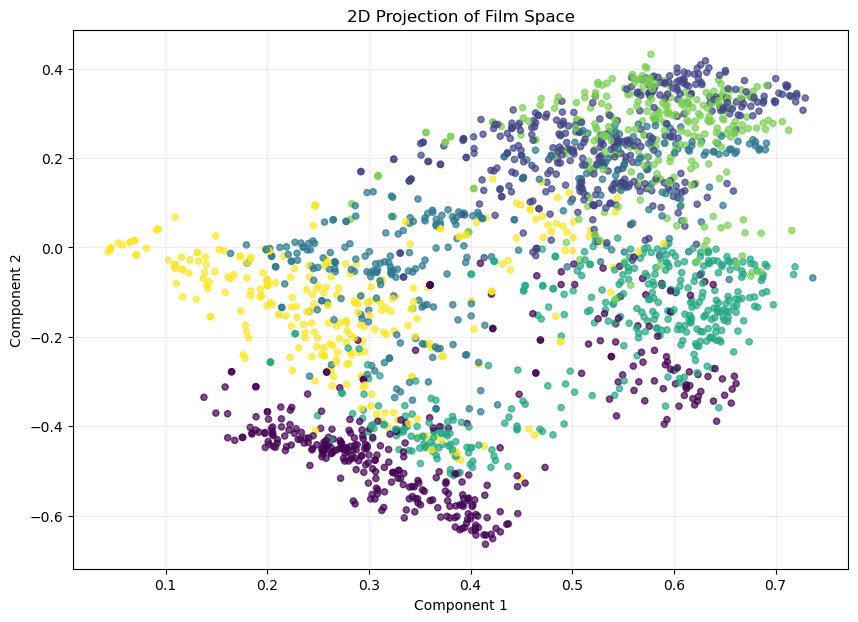

In [37]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    plot_df["x"],
    plot_df["y"],
    c=plot_df["cluster"],
    s=20,
    alpha=0.7
)

plt.title("2D Projection of Film Space")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.grid(alpha=0.2)
plt.show()

In [38]:
representative_indices_all = []

for cluster_id in sorted(df["cluster"].unique()):
    reps = get_representative_films(
        matrix=X_model_for_clustering,
        model=kmeans_model,
        labels=cluster_labels,
        cluster_id=cluster_id,
        df=df,
        title_col=display_col,
        top_n=2
    )
    representative_indices_all.extend(reps.index.tolist())

representative_indices_all = sorted(set(representative_indices_all))

## 10. Save clustering outputs

We save the final clustering assignments and the cluster profile table for later analysis and reporting.

In [39]:
clustered_films_path = RESULTS_DIR / "clustered_films.csv"
cluster_profiles_path = RESULTS_DIR / "cluster_profiles.csv"
evaluation_plot_only_path = RESULTS_DIR / "evaluation_plot_only.csv"
evaluation_weighted_path = RESULTS_DIR / "evaluation_weighted.csv"

df.to_csv(clustered_films_path, index=False)
cluster_profiles_df.to_csv(cluster_profiles_path, index=False)
evaluation_plot_only.to_csv(evaluation_plot_only_path, index=False)
evaluation_weighted.to_csv(evaluation_weighted_path, index=False)

print("Saved clustered films to:", clustered_films_path)
print("Saved cluster profiles to:", cluster_profiles_path)
print("Saved evaluation tables to:", RESULTS_DIR)

NameError: name 'evaluation_plot_only' is not defined

## Output of this notebook

At the end of this notebook, we have:

- similarity exploration
- clustering results for selected values of k
- a final clustering solution
- interpretable cluster profiles
- a 2D visualization of the dataset

The next stage can extend this analysis with:
- Oscar recognition patterns by cluster
- IMDb rating and popularity comparisons
- positioning of new film loglines in the same feature space

In [43]:
from collections import Counter
from pathlib import Path
import pandas as pd

def build_cluster_profiles_for_run(
    df_clustered,
    model,
    matrix_for_clustering,
    X_terms_matrix,
    feature_names,
    display_col,
    top_terms_n=8,
    top_genres_n=5,
    top_keywords_n=5,
    top_representatives_n=5,
    save_path=None
):
    labels = df_clustered["cluster"].to_numpy()
    cluster_profiles = []

    for cluster_id in sorted(df_clustered["cluster"].unique()):
        cluster_df = df_clustered[df_clustered["cluster"] == cluster_id].copy()

        top_terms = top_terms_from_cluster_mean(
            X_terms_matrix,
            labels,
            cluster_id,
            feature_names,
            top_n=top_terms_n
        )

        genre_counter = Counter()
        for items in cluster_df["genres_list_parsed"]:
            genre_counter.update(items)

        keyword_counter = Counter()
        for items in cluster_df["keywords_filtered_parsed"]:
            keyword_counter.update(items)

        dominant_country = (
            cluster_df["mainCountry_clean"].mode().iloc[0]
            if "mainCountry_clean" in cluster_df.columns and not cluster_df["mainCountry_clean"].mode().empty
            else "unknown"
        )

        dominant_language = (
            cluster_df["firstLanguage_clean"].mode().iloc[0]
            if "firstLanguage_clean" in cluster_df.columns and not cluster_df["firstLanguage_clean"].mode().empty
            else "unknown"
        )

        representative_films = get_representative_films(
            matrix=matrix_for_clustering,
            model=model,
            labels=labels,
            cluster_id=cluster_id,
            df=df_clustered,
            title_col=display_col,
            top_n=top_representatives_n
        )[display_col].tolist()

        cluster_profiles.append({
            "cluster": int(cluster_id),
            "size": int(len(cluster_df)),
            "top_terms": ", ".join(top_terms),
            "top_genres": ", ".join([g for g, _ in genre_counter.most_common(top_genres_n)]),
            "top_keywords": ", ".join([k for k, _ in keyword_counter.most_common(top_keywords_n)]),
            "dominant_country": dominant_country,
            "dominant_language": dominant_language,
            "representative_films": " | ".join(representative_films),
        })

    cluster_profiles_df = pd.DataFrame(cluster_profiles).sort_values("cluster").reset_index(drop=True)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        cluster_profiles_df.to_csv(save_path, index=False)
        print(f"Saved cluster profiles to: {save_path}")

    return cluster_profiles_df

In [44]:
cluster_profiles_k5_df = build_cluster_profiles_for_run(
    df_clustered=df_k5,
    model=model_k5,
    matrix_for_clustering=matrix_options["weighted_hybrid"],
    X_terms_matrix=X_plot_tfidf,
    feature_names=tfidf_feature_names,
    display_col=display_col,
    save_path="outputs/text_clustering/results/cluster_profiles_k5.csv"
)

display(cluster_profiles_k5_df)

Saved cluster profiles to: outputs\text_clustering\results\cluster_profiles_k5.csv


,cluster,size,top_terms,top_genres,top_keywords,dominant_country,dominant_language,representative_films
0,0,382,"house, night, dr, soon, blood, mysterious, gro...","horror, thriller, mystery, drama, sci-fi","murder, blood, psychotronic film, death, violence",gb,en,Fran and Miriam are a pair of beautiful vampir...
1,1,276,"help, journey, father, adventure, named, frien...","adventure, fantasy, family, comedy, action","character name in title, rescue, explosion, ps...",gb,en,What is the price of freedom? Paul Johnson sai...
2,2,358,"friends, just, best, father, mother, friend, w...","comedy, drama, romance, crime, action","husband wife relationship, female nudity, kiss...",gb,en,"Maurice Russell, once a great actor, is now li..."
3,3,436,"police, bond, death, help, soon, finds, wife, ...","thriller, drama, crime, action, mystery","murder, death, violence, blood, female nudity",gb,en,"In London, Callum Aldrich is a young man that ..."
4,4,548,"war, mother, old, year, father, years, film, l...","drama, romance, biography, history, war","female nudity, husband wife relationship, deat...",gb,en,A young man is released from prison after many...


In [45]:
cluster_profiles_k6_df = build_cluster_profiles_for_run(
    df_clustered=df_k6,
    model=model_k6,
    matrix_for_clustering=matrix_options["weighted_hybrid"],
    X_terms_matrix=X_plot_tfidf,
    feature_names=tfidf_feature_names,
    display_col=display_col,
    save_path="outputs/text_clustering/results/cluster_profiles_k6.csv"
)

display(cluster_profiles_k6_df)

Saved cluster profiles to: outputs\text_clustering\results\cluster_profiles_k6.csv


,cluster,size,top_terms,top_genres,top_keywords,dominant_country,dominant_language,representative_films
0,0,363,"mother, old, year, father, meets, years, boy, ...","drama, romance, music, thriller, fantasy","female nudity, husband wife relationship, base...",gb,en,"In early adolescence, Humbert fell hopelessly ..."
1,1,367,"house, night, soon, blood, dr, mysterious, gro...","horror, thriller, mystery, drama, sci-fi","murder, blood, psychotronic film, death, violence",gb,en,Nerd Marty Rantzen is an outcast at Doddsville...
2,2,251,"bond, help, mission, named, father, evil, frie...","adventure, fantasy, family, comedy, action","explosion, murder, character name in title, re...",gb,en,This is the tale of Harry Potter (Daniel Radcl...
3,3,357,"friends, just, friend, best, father, mother, s...","comedy, drama, romance, crime, action","husband wife relationship, female nudity, kiss...",gb,en,"Romantic comedy: Will Hayes, a 30-something Ma..."
4,4,401,"police, finds, wife, soon, prison, killer, dea...","thriller, drama, crime, mystery, action","murder, death, violence, blood, female nudity",gb,en,"In London, Callum Aldrich is a young man that ..."
5,5,261,"war, film, german, british, king, ii, france, ...","drama, history, biography, war, documentary","based on true story, husband wife relationship...",gb,en,June 1944. Allied Forces stand on the brink: a...
